In [1]:
import pandas as pd
import scanpy as sc
import sys
from pathlib import Path
import numpy as np

In [2]:
# Add the IDEAS repo root to Python's import path
repo_root = Path("/home/csb/Saloni/IDEAS_ID/IDEAS")
sys.path.append(str(repo_root))

from computeID.functions_IDEAS import compute_ID

/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read('/home/csb/Saloni/IDEAS_ID/IDEAS/Data/GSE303505_TumorCells_normalized.h5ad')
print(adata)

AnnData object with n_obs × n_vars = 13924 × 32344
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'Type', 'mitoPercent', 'mitoRatio', 'log10GenesPerUMI', 'Annotation', 'Clone', 'batch'


In [4]:
id_local = compute_ID(
    adata,
    group="all",
    method="local_2nn",
    n_neighbors=50,
    normalization=True,
    full_output=True,
    id_score=True
)

print(id_local.shape)

Computing Intrinsic Dimension:   0%|          | 0/1 [00:00<?, ?it/s]

Computing ID:


Computing Intrinsic Dimension: 100%|██████████| 1/1 [01:51<00:00, 111.94s/it]

(13924, 1)


In [5]:
id_results = compute_ID(
    adata,
    group="Sample",
    method="2nn",
    n_samples=30,
    sample_size=0,
    normalization=True,
    full_output=True,
    id_score=True
)

/home/csb/Saloni/IDEAS_ID/IDEAS/computeID/functions_IDEAS.py:41: UserWarning: 'sample_size' not specified: automatically set to 636 (80% of smallest group size: 13924)
  warnings.warn(f"'sample_size' not specified: automatically set to {sample_size} (80% of smallest group size: {n_obs})")
Computing Intrinsic Dimension:   0%|          | 0/5 [00:00<?, ?it/s]

Computing ID for Sample E:


Computing Intrinsic Dimension:  20%|██        | 1/5 [00:05<00:23,  5.88s/it]

Computing ID for Sample EM1:


Computing Intrinsic Dimension:  40%|████      | 2/5 [00:11<00:17,  5.83s/it]

...

Computing Intrinsic Dimension:  60%|██████    | 3/5 [00:17<00:11,  5.83s/it]

Computing ID for Sample EM3:


Computing Intrinsic Dimension:  80%|████████  | 4/5 [00:23<00:05,  5.82s/it]

Computing ID for Sample M:


Computing Intrinsic Dimension: 100%|██████████| 5/5 [00:29<00:00,  5.83s/it]


In [6]:
print(id_results.shape)
display(id_results.head())

print(id_local.shape)
print(id_local.head())

(30, 5)


,E,EM1,EM2,EM3,M
1,0.366573,0.678995,0.267091,0.154925,0.638926
2,0.434437,0.788255,0.361990,0.073729,0.968781
3,0.223274,0.734011,0.244523,0.161165,0.580152
4,0.191411,0.589183,0.272948,0.125216,0.909922
5,0.327880,1.000000,0.357586,0.052627,0.664237


(13924, 1)
                                    ID
AAACCAGGTGCGATAAACTTTAGG-1-0  0.420520
AAACCGGTCCTGCCAGACTTTAGG-1-0  0.582540
AAACCGGTCGAACCGAACTTTAGG-1-0  0.157976
AAAGCCTAGGCAAGTTACTTTAGG-1-0  0.187279
AAAGCCTAGTTGGATAACTTTAGG-1-0  0.402510


In [7]:
id_summary = pd.DataFrame({
    "Sample": id_results.columns,
    "ID": id_results.mean(axis=0),
    "SD": id_results.std(axis=0)
})

display(id_summary)

id_local_df = id_local.copy()

id_local_df.index.name = "cell"

id_local_df.to_excel(
    "/home/csb/Saloni/SCENT/data/ID/Pattabiraman_ID_local.xlsx"
)

print(id_local_df.head())

,Sample,ID,SD
E,E,0.330063,0.084731
EM1,EM1,0.707555,0.134255
EM2,EM2,0.384236,0.115983
EM3,EM3,0.150903,0.080470
M,M,0.691262,0.134813


                                    ID
AAACCAGGTGCGATAAACTTTAGG-1-0  0.420520
AAACCGGTCCTGCCAGACTTTAGG-1-0  0.582540
AAACCGGTCGAACCGAACTTTAGG-1-0  0.157976
AAAGCCTAGGCAAGTTACTTTAGG-1-0  0.187279
AAAGCCTAGTTGGATAACTTTAGG-1-0  0.402510


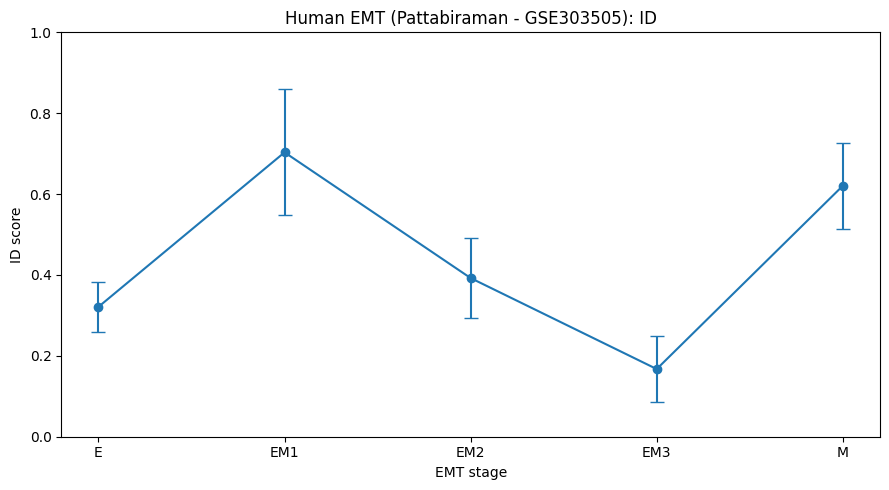

In [8]:
import matplotlib.pyplot as plt

doses = id_summary["Sample"].astype(str)

plt.figure(figsize=(9, 5))

plt.errorbar(
    range(len(id_summary)),
    id_summary["ID"],
    yerr=id_summary["SD"],
    fmt="o-",
    capsize=5
)

plt.xticks(
    range(len(id_summary)),
    doses
)

plt.xlabel("EMT stage")
plt.ylabel("ID score")
plt.ylim(0, 1)
plt.title("Human EMT (Pattabiraman - GSE303505): ID")

plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import f_oneway
import pandas as pd

id_long = id_results.melt(
    var_name="Sample",
    value_name="ID"
)

print(id_long.head())

groups = [
    group["ID"].values
    for _, group in id_long.groupby("Sample")
]

F_stat, p_value = f_oneway(*groups)

print(f"F-statistic = {F_stat:.4f}")
print(f"p-value = {p_value:.4e}")



  Sample        ID
0      E  0.334090
1      E  0.296251
2      E  0.304169
3      E  0.297231
4      E  0.319046
F-statistic = 129.9082
p-value = 6.6535e-47


In [10]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Sample"],
    alpha=0.05
)

print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     E    EM1    0.382    0.0  0.3068  0.4572   True
     E    EM2   0.0711 0.0735 -0.0041  0.1463  False
     E    EM3  -0.1539    0.0 -0.2291 -0.0787   True
     E      M   0.2992    0.0   0.224  0.3744   True
   EM1    EM2  -0.3109    0.0 -0.3861 -0.2357   True
   EM1    EM3  -0.5359    0.0 -0.6111 -0.4607   True
   EM1      M  -0.0828 0.0231  -0.158 -0.0076   True
   EM2    EM3   -0.225    0.0 -0.3002 -0.1498   True
   EM2      M   0.2281    0.0  0.1529  0.3033   True
   EM3      M   0.4531    0.0  0.3779  0.5283   True
----------------------------------------------------


In [11]:
cell_counts = (
    adata.obs["Sample"]
    .value_counts()
    .sort_index()
)

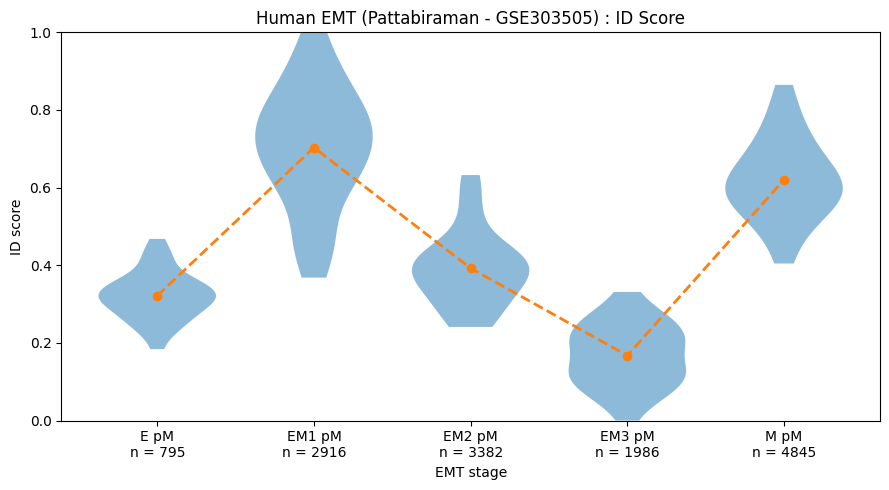

In [13]:
# ------------------------------------------------------------
# Prepare groups in dose order
# ------------------------------------------------------------

doses = sorted(id_long["Sample"].unique())

id_groups = [
    id_long.loc[id_long["Sample"] == dose, "ID"].values
    for dose in doses
]

id_means = [
    np.mean(group)
    for group in id_groups
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(doses))

# Violin plots
parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Make violins slightly transparent
for body in parts["bodies"]:
    body.set_alpha(0.5)

# ------------------------------------------------------------
# Dashed line connecting mean ID scores
# ------------------------------------------------------------

ax.plot(
    positions,
    id_means,
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=6
)

# ------------------------------------------------------------
# X-axis labels: dose + number of cells
# ------------------------------------------------------------

labels = [
    f"{dose} pM\nn = {cell_counts.loc[dose]}"
    for dose in doses
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

# ------------------------------------------------------------
# Labels / formatting
# ------------------------------------------------------------

ax.set_xlabel("EMT stage")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)

ax.set_title("Human EMT (Pattabiraman - GSE303505) : ID Score")

plt.tight_layout()
plt.show()

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     E    EM1    0.382    0.0  0.3068  0.4572   True
     E    EM2   0.0711 0.0735 -0.0041  0.1463  False
     E    EM3  -0.1539    0.0 -0.2291 -0.0787   True
     E      M   0.2992    0.0   0.224  0.3744   True
   EM1    EM2  -0.3109    0.0 -0.3861 -0.2357   True
   EM1    EM3  -0.5359    0.0 -0.6111 -0.4607   True
   EM1      M  -0.0828 0.0231  -0.158 -0.0076   True
   EM2    EM3   -0.225    0.0 -0.3002 -0.1498   True
   EM2      M   0.2281    0.0  0.1529  0.3033   True
   EM3      M   0.4531    0.0  0.3779  0.5283   True
----------------------------------------------------


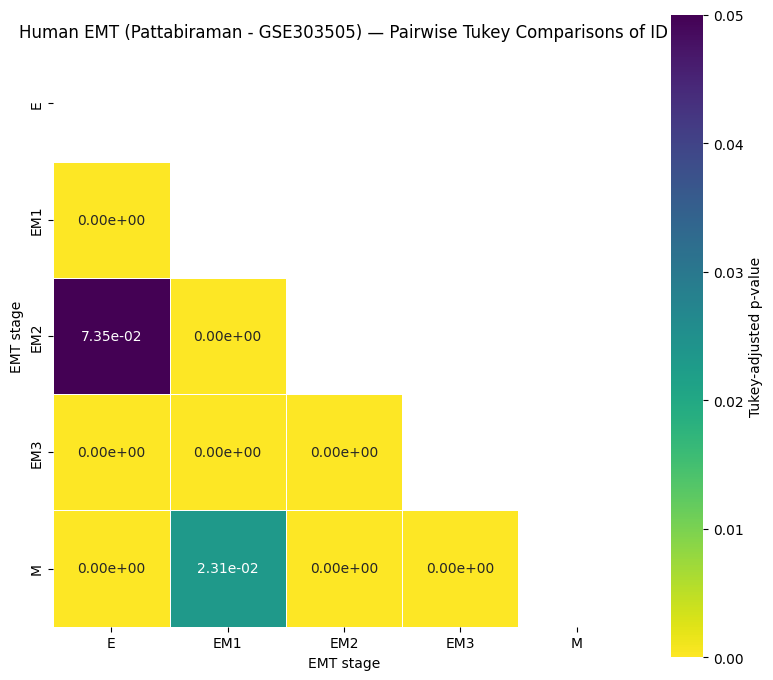

In [14]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST
# ============================================================

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Sample"],
    alpha=0.05
)

print(tukey)


# ============================================================
# TIME ORDER
# ============================================================

doses = sorted(id_long["Sample"].unique())


# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_df = pd.DataFrame(
    data=tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

# Make sure p-adj is numeric
tukey_df["p-adj"] = tukey_df["p-adj"].astype(float)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

tukey_matrix = pd.DataFrame(
    np.nan,
    index=doses,
    columns=doses
)


for _, row in tukey_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]
    p_adj = row["p-adj"]

    tukey_matrix.loc[group1, group2] = p_adj
    tukey_matrix.loc[group2, group1] = p_adj


# ============================================================
# HEATMAP
# LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "Human EMT (Pattabiraman - GSE303505) — Pairwise Tukey Comparisons of ID"
)

plt.xlabel("EMT stage")
plt.ylabel("EMT stage")

plt.tight_layout()
plt.show()